# Optic analysis

### USER INPUT

In [1]:
MINE_POLYGON = "klikowa_sciezki_mine_polygon.geojson"
VOIVODESHIP = "malopolskie"
START_DATE = "2024-08-28"
END_DATE = "2024-09-30"

### 1. Imports and parameters

In [2]:
import ee
import json
import geemap
import requests
from io import BytesIO
from pathlib import Path
from datetime import datetime
from pyproj import Transformer
import matplotlib.pyplot as plt
from PIL import Image as PilImage
from shapely.geometry import shape
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.ops import unary_union, transform
from IPython.display import Image as NotebookImage
from IPython.display import display, Image as NotebookImage

AOI = None
HOME_DIR = Path(r"c:\space_technologies\Kopalnie\open-pit-mining\optic")
POLYGON_PATH = HOME_DIR / "mines_polygons" / MINE_POLYGON
OUTPUT_DIR = HOME_DIR / "output_optic_maps"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

c:\space_technologies\Kopalnie\open-pit-mining\.venv\lib\site-packages\google\oauth2\__init__.py:40: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
c:\space_technologies\Kopalnie\open-pit-mining\.venv\lib\site-packages\google\auth\__init__.py:54: FutureWarning: You are using a Python version 3.9 past its end of life. Google will update google-auth with critical bug fixes on a best-effort basis, but not with any other fixes or features. Please upgrade your Python version, and then update google-auth.
  warnings.warn(eol_message.format("3.9"), FutureWarning)
c:\space_technologies\Kopalnie\open-pit-mining\.venv\lib\site-packages\google\api_core\_python_version_support.py:242: FutureWarning: You are using a non-supported Pyth

### 2. Prepare AOI, mine and reference layers

In [3]:
def mine_geometry(path):
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    feats = data["features"] if data.get("type") == "FeatureCollection" else [data]
    geom = unary_union([shape(f["geometry"]) for f in feats])
    return ee.Geometry(geom.__geo_interface__)


def make_polygon_buffer(path):
    data = json.loads(Path(path).read_text(encoding="utf-8"))
    feats = data["features"] if data.get("type") == "FeatureCollection" else [data]
    geom = unary_union([shape(f["geometry"]) for f in feats])

    lon, lat = geom.centroid.x, geom.centroid.y
    zone = int((lon + 180) // 6) + 1
    utm_epsg = (32600 if lat >= 0 else 32700) + zone

    to_utm = Transformer.from_crs("EPSG:4326", f"EPSG:{utm_epsg}", always_xy=True)
    to_wgs = Transformer.from_crs(f"EPSG:{utm_epsg}", "EPSG:4326", always_xy=True)

    geom_utm = transform(to_utm.transform, geom)
    bbox_utm = geom_utm.buffer(250).envelope
    bbox_wgs = transform(to_wgs.transform, bbox_utm)

    print("polygon bounds:", geom.bounds)
    print("AOI bounds:", bbox_wgs.bounds)

    return ee.Geometry(bbox_wgs.__geo_interface__)


def reference_layers(voivodeship):
    folder = "projects/mining-457808/assets/%s" % voivodeship
    names = ["buildings", "residential", "industrial",  "water", "waterways", "railways"]

    layers = {
        name: ee.FeatureCollection("%s/%s" % (folder, name))
        for name in names
    }
    layers["mines_active"] = ee.FeatureCollection("projects/mining-457808/assets/mines/mines_active_poland")
    layers["mines_archival"] = ee.FeatureCollection("projects/mining-457808/assets/mines/mines_archival_poland")
    
    return layers


### 3. Stack of Sentinel-2 images

In [4]:
def image_label(image):
    meta = ee.Dictionary({
        "id": image.get("system:index"),
        "date": ee.Date(image.get("system:time_start")).format("YYYY-MM-dd"),
    }).getInfo()
    return "%s %s" % (meta["date"], meta["id"])


def _contains_whole_aoi(image):
    contains_aoi = bool(image.geometry().contains(AOI, ee.ErrorMargin(1)).getInfo())
    return contains_aoi


def _check_clouds(image):
    scl = image.select("SCL")
    cloud = (scl.eq(3).Or(scl.eq(8)).Or(scl.eq(9)).Or(scl.eq(10)).rename("cloud"))
    clouds_fraction = cloud.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=AOI,
        scale=20,
        maxPixels=1e8,
    ).get("cloud").getInfo()
    return clouds_fraction


def find_sentinel_2_images():
    print("Searching for Sentinel-2 images ...")
    print("  date range: %s - %s" % (START_DATE, END_DATE))

    start = datetime.combine(
        datetime.strptime(START_DATE, "%Y-%m-%d").date(),
        datetime.min.time(),
    )
    end = datetime.combine(
        datetime.strptime(END_DATE, "%Y-%m-%d").date(),
        datetime.max.time(),
    )

    col = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(AOI)
        .filterDate(start, end)
        .sort("system:time_start")
    )

    total = col.size().getInfo()
    if not total:
        return []
    print("  images found: %d" % total)

    listed = col.toList(total)
    images_stack = []
    for image in range(total):
        image = ee.Image(listed.get(image))
        label = image_label(image)
        if not _contains_whole_aoi(image):
            print("  reject: %s, AOI is not fully inside the scene" % label)
            continue

        clouds = _check_clouds(image)
        if clouds is None or clouds > 0:
            print("  reject: %s, clouds cover AOI" % label)
            continue
        print("  accept: %s" % label)
        images_stack.append(image)

    print("  images accepted: %d" % len(images_stack))
    assert len(images_stack) > 0, ("No suitable images were found for analysis.")
    return images_stack


### 4. Bare soil layer

In [5]:
def calculate_bare_soil(image, ones, mine):
    ndvi = image.normalizedDifference(["B8", "B4"]).rename("NDVI")
    bare_soil = ndvi.lt(0.18)
    outside = ones.where(ee.Image.constant(1).clip(mine).eq(1), 0)
    exceeded = bare_soil.updateMask(outside)
    return exceeded, bare_soil

### 5. Reference layers

In [6]:
def _archival_outside_mine(feature, mine):
    geom = feature.geometry().intersection(AOI, 1).difference(mine, 1)
    return feature.setGeometry(geom).set("outside_area", geom.area(1))


def _mask_out(image, features, canvas):
    painted = ee.Image(0).byte().paint(features, 1)
    return image.updateMask(canvas.where(painted.eq(1), 0))


def _clip_to_aoi(features):
    def cut(feature):
        geom = feature.geometry().intersection(AOI, 1)
        return feature.setGeometry(geom).set("clip_area", geom.area(1))
    return features.map(cut).filter(ee.Filter.gt("clip_area", 0))


def filter_out_reference_layer(exceeded, ones, layers, mine):
    active_mines = (
        layers["mines_active"]
        .filterBounds(AOI)
        .filter(ee.Filter.intersects(".geo", mine).Not())
    )
    archival_mines = (
        layers["mines_archival"]
        .filterBounds(AOI)
        .map(lambda feature: _archival_outside_mine(feature, mine))
        .filter(ee.Filter.gt("outside_area", 0))
    )

    buildings = layers["buildings"].filterBounds(AOI)
    residential = layers["residential"].filterBounds(AOI)
    industrial = layers["industrial"].filterBounds(AOI)
    railways = layers["railways"].filterBounds(AOI).map(lambda feature: feature.buffer(10))
    waterways = layers["waterways"].filterBounds(AOI).map(lambda feature: feature.buffer(10))
    water = layers["water"].filterBounds(AOI)

    reference_layers = {
        "residential": residential,
        "industrial": industrial,
        "buildings": buildings,
        "railways": railways,
        "archival mines": archival_mines,
        "active mines": active_mines,
        "waterways": waterways,
        "water": water,
    }

    for features in reference_layers.values():
        exceeded = _mask_out(exceeded, features, ones)

    clipped_layers = {
        name: _clip_to_aoi(features)
        for name, features in reference_layers.items()
    }
    return exceeded, clipped_layers
    

### 6. Vectorization

In [7]:
def exceeded_to_vectors(exceeded, image, mine):
    projection = image.select("B4").projection()
    exceeded_vectors = exceeded.selfMask().reduceToVectors(
        geometry=AOI,
        crs=projection.crs(),
        scale=10,
        geometryType="polygon",
        eightConnected=True,
        maxPixels=1e8,
    )
    exceeded_vectors = exceeded_vectors.filter(ee.Filter.intersects(".geo", mine.buffer(10)))
    outside_geom = AOI.difference(mine)

    exceeded_vectors = exceeded_vectors.map(
        lambda feature: feature.setGeometry(
            feature.geometry().buffer(10, 1).intersection(outside_geom)
        )
    )
    return exceeded_vectors


In [8]:
def styled_overlay(features, hex_color):
    return features.style(color=hex_color, fillColor=hex_color + "80", width=2)


def show_map(analysis, rgb, mine, reference_layers_colors):
    rgb_vis = {"bands": ["B4", "B3", "B2"], "min": 0, "max": 3000}
    bare_soil_vis = {"min": 0, "max": 255}
    polygon_style = {"color": "00FF00", "fillColor": "00000000", "width": 2}
    exceeded_style = {"color": "FF0000", "fillColor": "FF0000", "width": 1}

    m = geemap.Map()
    m.centerObject(AOI, zoom=15)
    m.add_layer(analysis["rgb"], rgb_vis, "orthophotomap")
    m.add_layer(rgb, bare_soil_vis, "bare soil")
    for name, features in analysis["overlays"].items():
        m.add_layer(styled_overlay(features, reference_layers_colors[name]), {}, name)
    m.add_layer(analysis["exceeded"].style(**exceeded_style), {}, "exceeded")
    m.add_layer(mine.style(**polygon_style), {}, "mining area")
    display(m)
    

def visualization(analysis, mine, label):
    reference_layers_colors = {
        "buildings": "CD853F",
        "residential": "FFDAB9",
        "industrial": "F0E68C",
        "waterways": "B0E0E6",
        "water": "B0E0E6",
        "railways": "808080",
        "archival mines": "9370DB",
        "active mines": "BA55D3"
    }

    rgb_scaled = analysis["rgb"].unitScale(0, 3000).multiply(255)
    bare_soil_mask = analysis["bare_soil"].unmask(0)
    rgb_with_bare_soil = rgb_scaled.where(bare_soil_mask, ee.Image.constant([255, 255, 255])).byte()
    for name, features in analysis["overlays"].items():
        final = rgb_with_bare_soil.blend(styled_overlay(features, reference_layers_colors[name]))

    red = ee.Image.constant([255, 0, 0]).byte()
    green = ee.Image.constant([0, 255, 0]).byte()
    exceeded_mask = ee.Image(0).byte().paint(analysis["exceeded"], 1).selfMask()
    mine_layer = ee.FeatureCollection([ee.Feature(mine)])
    outline = ee.Image(0).byte().paint(mine_layer, 1, 2).selfMask()
    final = final.where(exceeded_mask, red).where(outline, green).clip(AOI)

    show_map(analysis, rgb_with_bare_soil, mine_layer, reference_layers_colors)

    date = datetime.strptime(label.split(" ")[0], "%Y-%m-%d").strftime("%d.%m.%Y")
    scene_id = label.split(" ", 1)[1].replace(":", "-")
    mine_name = Path(MINE_POLYGON).stem.removesuffix("_mine_polygon").replace("_", " ").title()

    out = OUTPUT_DIR / ("%s_%s_optic_map.png" % (date, scene_id))
    url = final.getThumbURL({"region": AOI, "dimensions": 768, "format": "png", "min": 0, "max": 255})
    response = requests.get(url, timeout=180)
    response.raise_for_status()

    image = plt.imread(BytesIO(response.content), format="png")
    img_h, img_w = image.shape[:2]
    map_w, margin, gap, title_h, legend_h = 7.0, 0.27, 0.24, 0.52, 1.70
    map_h = map_w * img_h / img_w
    fig_w = 2 * margin + map_w
    fig_h = 2 * margin + title_h + gap + map_h + gap + legend_h
    fig = plt.figure(figsize=(fig_w, fig_h), dpi=150)
    legend_ax = fig.add_axes([margin / fig_w, margin / fig_h, map_w / fig_w, legend_h / fig_h])
    image_ax = fig.add_axes(
        [margin / fig_w, (margin + legend_h + gap) / fig_h, map_w / fig_w, map_h / fig_h]
    )

    fig.text(
        0.5, 1 - margin / fig_h, "Mining Activity Outside the Permitted Area",
        fontsize=16, fontweight="bold", ha="center", va="top",
    )
    fig.text(
        0.5, 1 - (margin + 0.34) / fig_h, "%s  |  %s" % (mine_name, date),
        fontsize=12, color="black", ha="center", va="top",
    )
    image_ax.imshow(image)
    image_ax.set_axis_off()
    legend_ax.set_axis_off()

    legend_handles = [
        Patch(facecolor="#FF0000", edgecolor="#FF0000", label="extraction outside mine area"),
        Line2D([0], [0], color="#00FF00", linewidth=2, label="mine area boundary"),
        Patch(facecolor="#FFFFFF", edgecolor="#000000", label="bare soil"),
    ]
    legend_handles.extend(
        Patch(facecolor="#" + color, edgecolor="#" + color, alpha=0.5, label=name.lower())
        for name, color in reference_layers_colors.items()
    )
    legend = legend_ax.legend(
        handles=legend_handles,
        title="Legend",
        loc="upper center",
        bbox_to_anchor=(0.5, 1),
        borderaxespad=0,
        borderpad=0.8,
        ncol=2,
        columnspacing=2.5,
        frameon=True,
        fancybox=False,
        edgecolor="#CCCCCC",
        facecolor="white",
        framealpha=1,
        fontsize=10.5,
        title_fontsize=12,
    )
    legend._legend_box.sep = 1.0 * 10.5

    fig.savefig(out, facecolor="white")
    plt.close(fig)
    print("Saved map: %s" % out)
    display(NotebookImage(filename=str(out)))
    return out


def show_optic_gif(paths):
    frames = [PilImage.open(path).convert("RGB") for path in paths]
    gif_path = OUTPUT_DIR / "optic_maps.gif"
    frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=1000, loop=0)
    print("Saved GIF: %s" % gif_path)
    display(NotebookImage(filename=str(gif_path)))


polygon bounds: (20.93842142427692, 50.0520799750745, 20.946199669240094, 50.05767037667018)
AOI bounds: (20.93492740251411, 50.049825852955315, 20.94969399691524, 50.059920183695425)
Searching for Sentinel-2 images ...
  date range: 2024-08-28 - 2024-09-30
  images found: 7
  accept: 2024-08-31 20240831T093549_20240831T093823_T34UDA
  reject: 2024-09-05 20240905T094031_20240905T094031_T34UDA, clouds cover AOI
  reject: 2024-09-10 20240910T094029_20240910T094445_T34UDA, clouds cover AOI
  accept: 2024-09-15 20240915T094031_20240915T094048_T34UDA
  reject: 2024-09-20 20240920T094029_20240920T094449_T34UDA, clouds cover AOI
  reject: 2024-09-25 20240925T094031_20240925T094108_T34UDA, clouds cover AOI
  reject: 2024-09-30 20240930T094029_20240930T094136_T34UDA, clouds cover AOI
  images accepted: 2


Map(center=[50.05487325097281, 20.942311473178194], controls=(WidgetControl(options=['position', 'transparent_…

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\optic\output_optic_maps\31.08.2024_20240831T093549_20240831T093823_T34UDA_optic_map.png


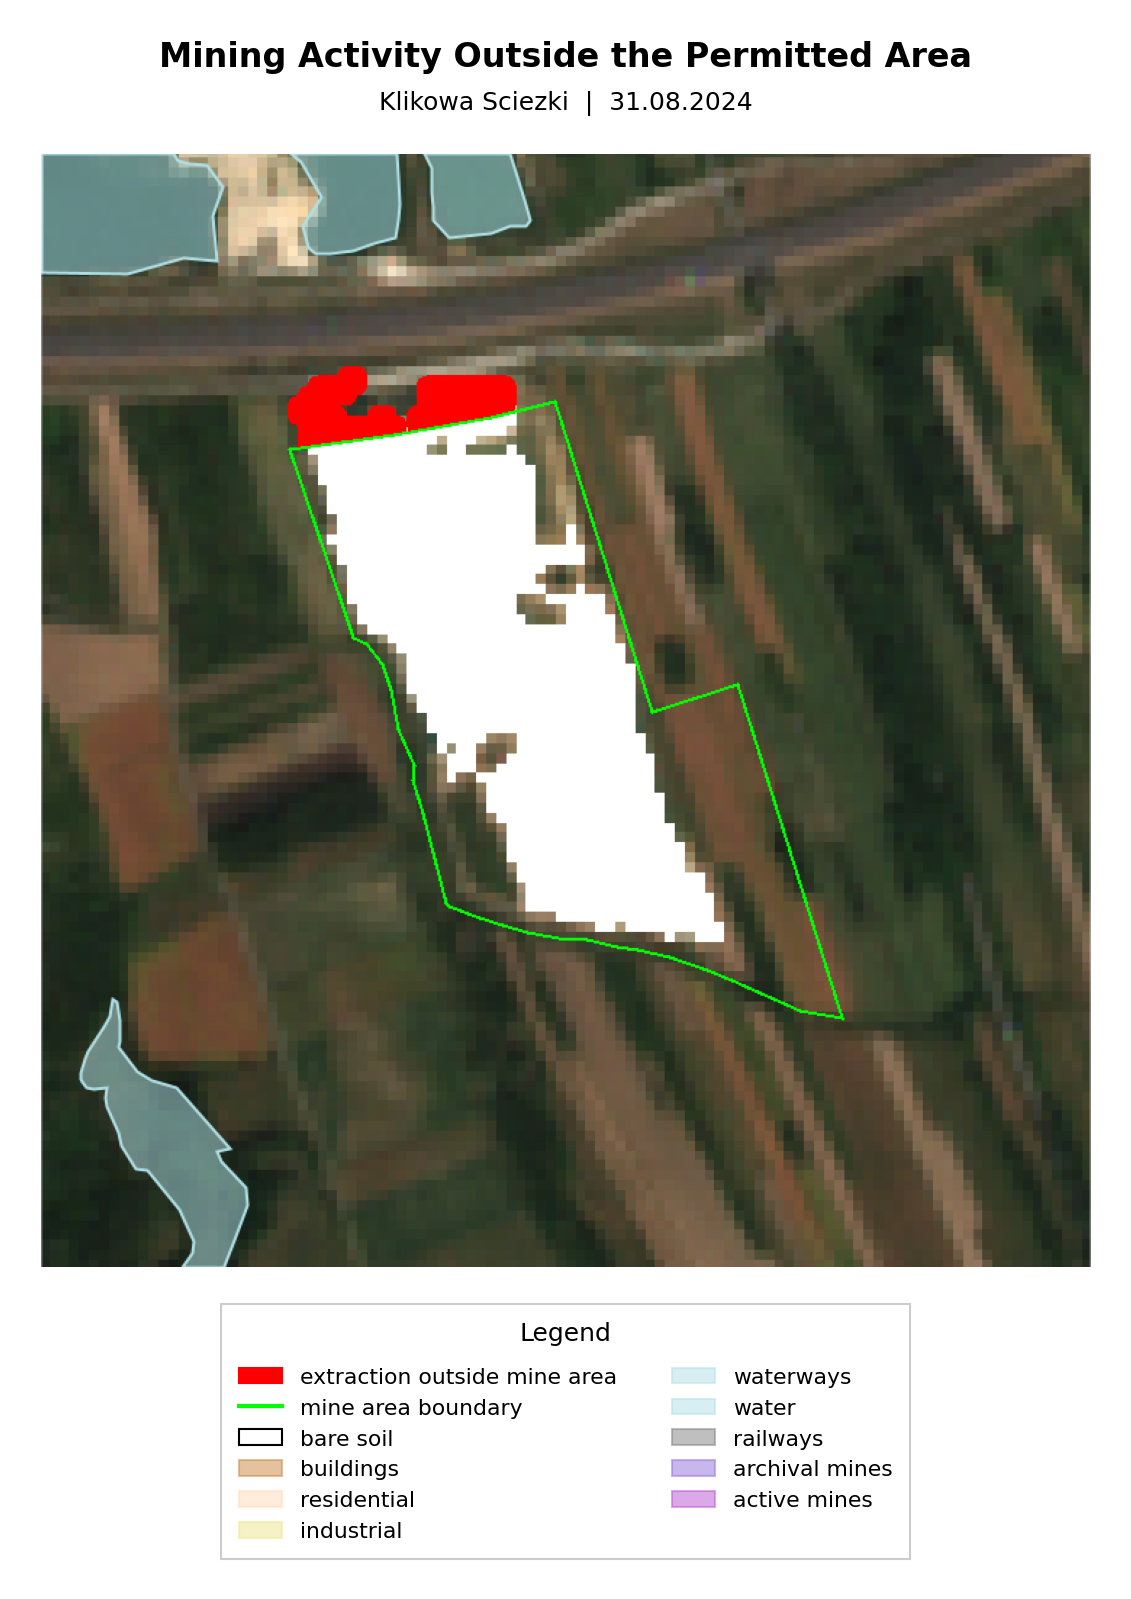

Map(center=[50.05487325097281, 20.942311473178194], controls=(WidgetControl(options=['position', 'transparent_…

Saved map: c:\space_technologies\Kopalnie\open-pit-mining\optic\output_optic_maps\15.09.2024_20240915T094031_20240915T094048_T34UDA_optic_map.png


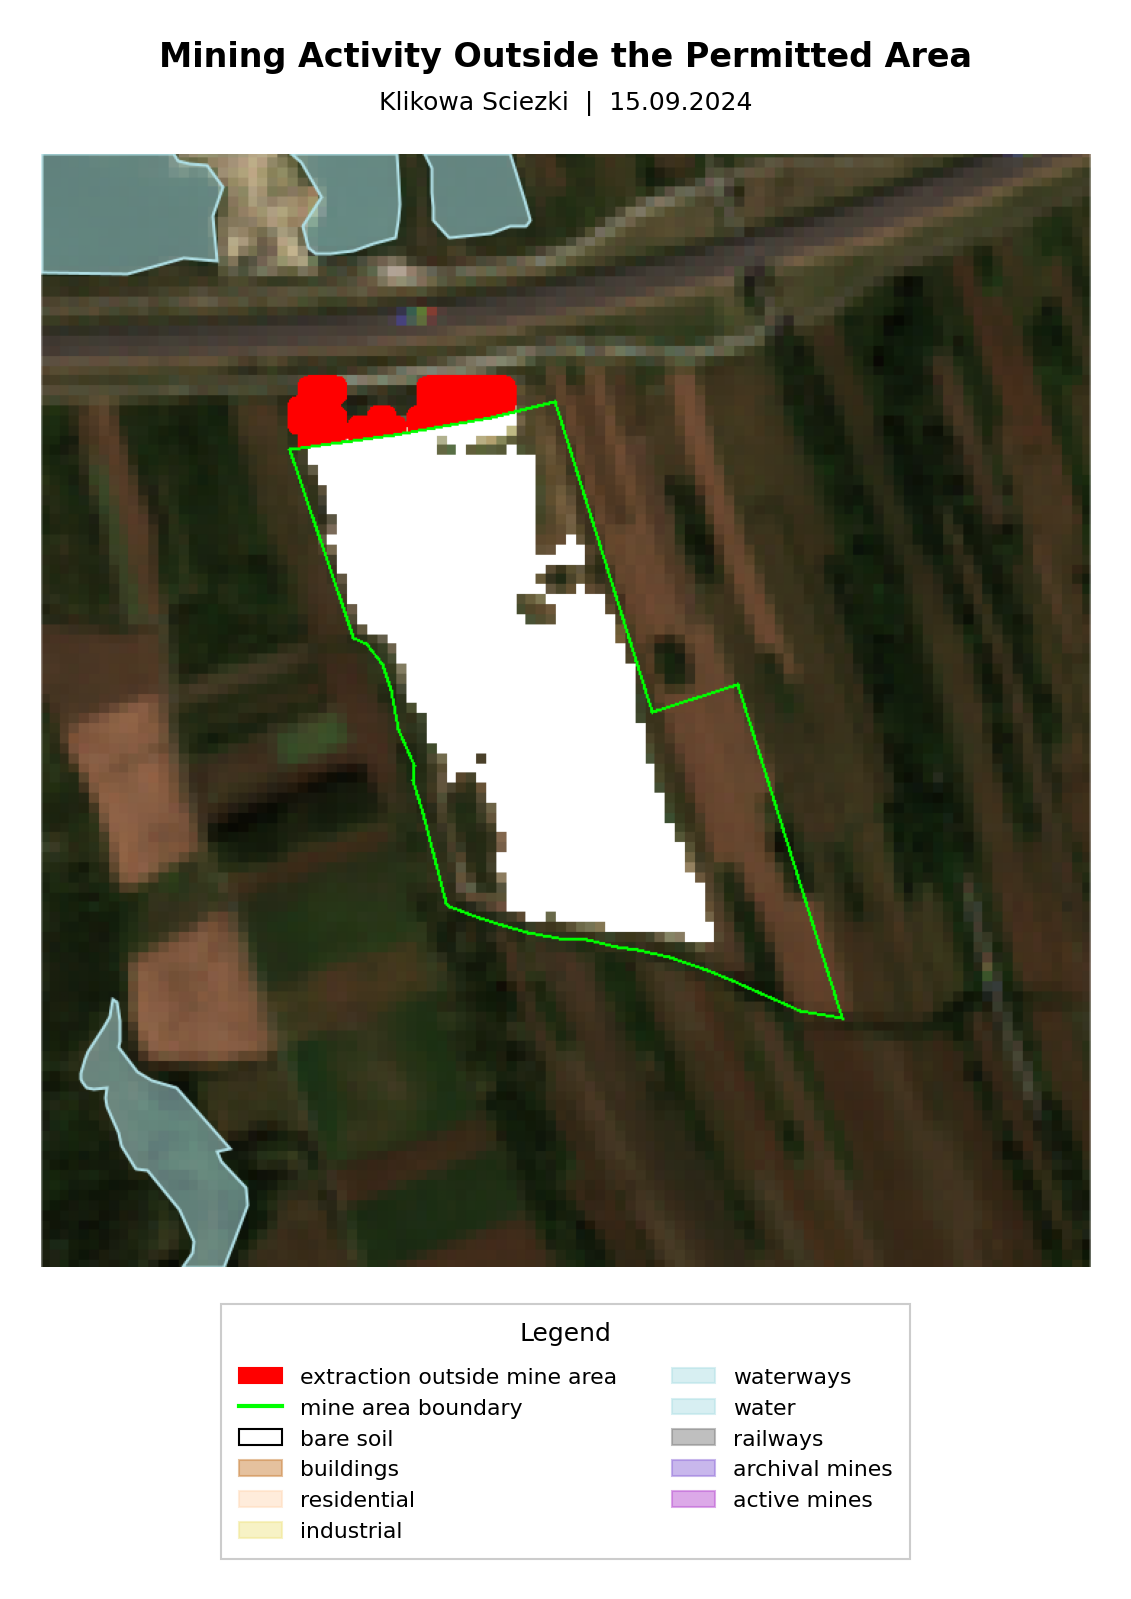

Saved GIF: c:\space_technologies\Kopalnie\open-pit-mining\optic\output_optic_maps\optic_maps.gif


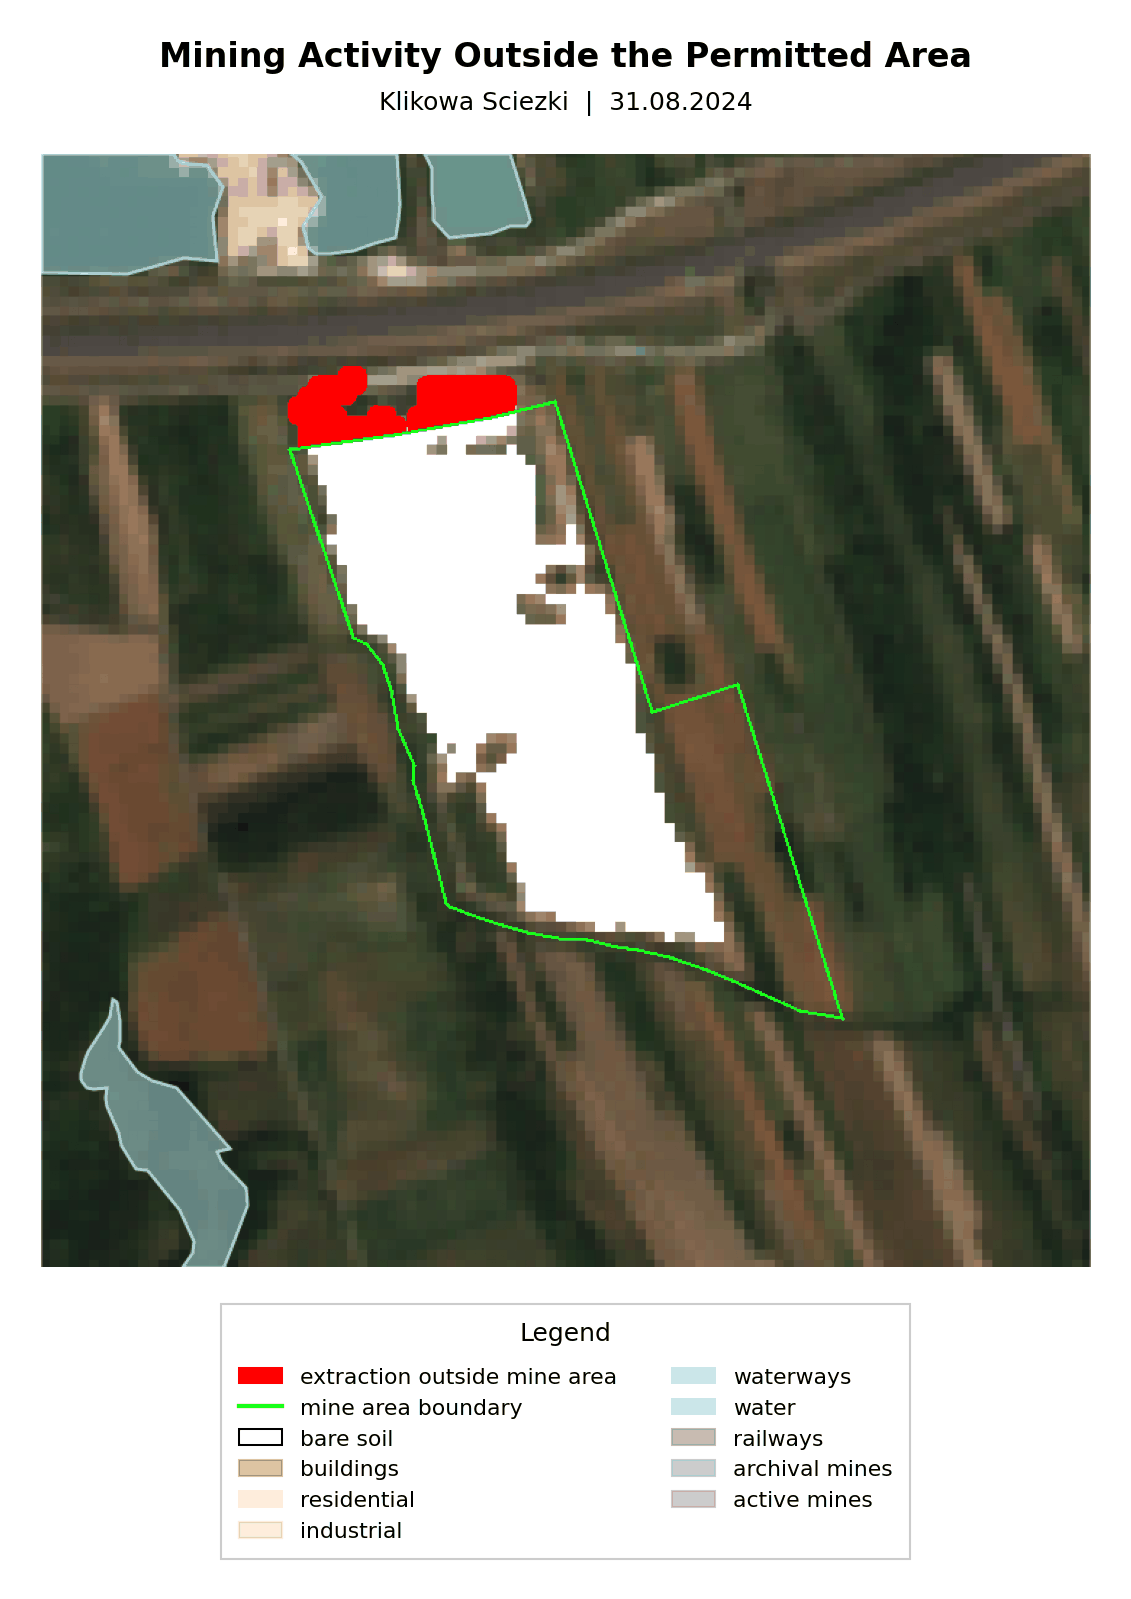

In [9]:
def analyze_scene(image, mine, layers):
    image = image.clip(AOI)
    ones = ee.Image.constant(1).clip(AOI)
    rgb = image.select(["B4", "B3", "B2"])

    exceeded, bare_soil = calculate_bare_soil(image, ones, mine)
    exceeded, clipped_layers = filter_out_reference_layer(exceeded, ones, layers, mine)
    exceeded = exceeded_to_vectors(exceeded, image, mine)

    return {
        "rgb": rgb,
        "bare_soil": bare_soil.clip(mine),
        "exceeded": exceeded,
        "overlays": clipped_layers,
    }

ee.Initialize(project="mining-457808")

mine = mine_geometry(POLYGON_PATH)
AOI = make_polygon_buffer(POLYGON_PATH)
layers = reference_layers(VOIVODESHIP)

images_stack = find_sentinel_2_images()
saved_maps = []

for image in images_stack:
    label = image_label(image)
    optic_analysis = analyze_scene(image, mine, layers)

    output_map = visualization(optic_analysis, mine, label)
    saved_maps.append(output_map)

show_optic_gif(saved_maps)
